GPU Tesla T4
Using device cuda
Epoch 1/5 | Loss: 325.5291
Epoch 2/5 | Loss: 134.3790
Epoch 3/5 | Loss: 90.9076
Epoch 4/5 | Loss: 69.1781
Epoch 5/5 | Loss: 54.8349
Total Accuracy: 97.50%
Model saved successfully!


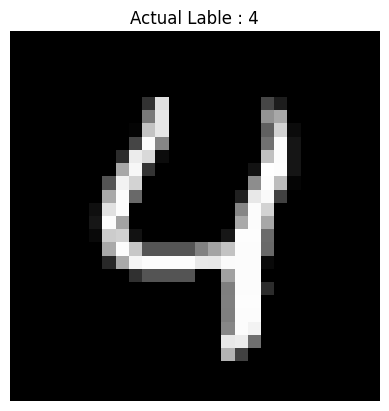

User picked image index 4
Actual Label 4
Model Prediction 4


In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision.datasets import MNIST
from torchvision import transforms
from torch.utils.data import DataLoader

def load_data():
    transform = transforms.ToTensor()

    train_data = MNIST(
        root="/content/data",
        train= True,
        download= True,
        transform= transform
    )

    test_data = MNIST(
        root="/content/data",
        train= False,
        download= True,
        transform= transform
    )

    train_loader = DataLoader(
        train_data,
        batch_size= 64,
        shuffle= True
    )

    test_loader = DataLoader(
        test_data,
        batch_size= 64,
        shuffle= False
    )

    return train_loader, test_loader, test_data

def create_model():
    class DigitModel(nn.Module):

        def __init__(self):
            super().__init__()

            self.network = nn.Sequential(
                nn.Linear(28*28, 128),
                nn.ReLU(),

                nn.Linear(128, 64),
                nn.ReLU(),

                nn.Linear(64, 10)
            )

        def forward(self, x):
            return self.network(x)

    model = DigitModel()
    return model

def train_model(model, optimizer, loss_fn, train_loader, device):

    epochs = 5
    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in train_loader:
            images = images.view(images.size(0),-1).to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss +=loss.item()

            
        print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss:.4f}")

def evaluate_model( model, test_loader, device):

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for image, label in test_loader:
            image = image.view(image.size(0),-1).to(device)
            label = label.to(device)

            output = model(image)
            predictions = output.argmax(dim=1)

            correct += (predictions == label).sum().item()
            total += label.size(0)

    accuracy = 100*(correct/total)
    return accuracy


train_loader, test_loader, test_data = load_data()

if torch.cuda.is_available():
    print("GPU", torch.cuda.get_device_name(0))
else:
    print("CPU")


device ="cuda" if torch.cuda.is_available() else "cpu"
print("Using device", device)

model = create_model().to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

train_model(model, optimizer, loss_fn, train_loader, device)

accuracy = evaluate_model(model, test_loader, device)

print(f"Total Accuracy: {accuracy:.2f}%")

# Create the models folder
os.makedirs("/content/models", exist_ok=True)

# Save the trained model
torch.save(model.state_dict(), "/content/models/mnist_model.pth")

print("Model saved successfully!")

index = 4
image, true_label = test_data[index]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual Lable : {true_label}")
plt.axis("off")
plt.show()

image_flat = image.view(1, -1).to(device)

with torch.no_grad():
    output = model(image_flat)
    predicted_label = output.argmax(dim=1).item()

print("User picked image index", index)
print("Actual Label", true_label)
print("Model Prediction", predicted_label)